# Trabajo Práctico — Seguimiento y caracterización de satélites

## Etapa 1: Análisis del catálogo

In [1]:
from datetime import datetime, timezone

from catalogo import (
    leer_satelites,
    contar_por_grupo,
    lanzamientos_por_anio,
    grupo
)

from funciones_base import epoch_medio

from satelite import crear_satelites

from analisis import (
    contar_por_tipo,
    mas_bajo,
    mas_alto,
    en_zona,
    ordenar_por,
    top_n,
    resumen_por_grupo
)

## 1. Carga de datos

En esta sección se carga el catálogo de satélites y se analiza
la antigüedad de los datos orbitales utilizados.

In [2]:
registros = leer_satelites("datos/satelites.json")

momento = datetime.now(timezone.utc)

satelites = crear_satelites(registros, momento)

fecha = epoch_medio(registros)
diferencia = momento - fecha

print("Cantidad de registros:", len(registros))
print("Satélites creados:", len(satelites))
print("Satélites descartados:", len(registros) - len(satelites))
print("Fecha media de las observaciones:", fecha)
print("Días transcurridos:", diferencia.days)

Cantidad de registros: 16710
Satélites creados: 16681
Satélites descartados: 29
Fecha media de las observaciones: 2026-10-14 06:30:18.482258+00:00
Días transcurridos: 15


## 2. Grupos
1. ¿Cuántos satélites hay de cada grupo?
2. ¿Qué porcentaje del catálogo pertenece a Starlink?

In [3]:
conteos = contar_por_grupo(registros)
starlink = conteos['Starlink']
total = len(registros)
porcentaje = (starlink/total) *100

print("Cantidad de satelites de cada grupo:", conteos)
print("Porcentaje del catalogo que pertenece a Starlink:", porcentaje)

Cantidad de satelites de cada grupo: {'Otros': 4075, 'GPS': 40, 'Globalstar': 36, 'BeiDou': 55, 'Iridium': 80, 'OneWeb': 651, 'Starlink': 11125, 'Qianfan': 257, 'Kuiper': 391}
Porcentaje del catalogo que pertenece a Starlink: 66.5769000598444


## 3. Lanzamientos por año
Cuántos satélites (de los activos hoy) se lanzaron cada año desde 2015. ¿En qué año se lanzaron más?

In [4]:
lanzamientos = lanzamientos_por_anio(registros)
print("Año-Cantidad")
for anio in sorted(lanzamientos):
    if anio >= 2015:
        print(anio, lanzamientos[anio])

maximo= max(lanzamientos, key=lanzamientos.get)
print(f"Año con mayor cantidad de lanzamientos: {maximo} ({lanzamientos[maximo]} satélites)")

Año-Cantidad
2015 96
2016 83
2017 136
2018 194
2019 145
2020 360
2021 994
2022 1718
2023 2266
2024 2429
2025 4289
2026 3285
Año con mayor cantidad de lanzamientos: 2025 (4289 satélites)


## 4. Tipos de órbita

Se clasifican los satélites según su altitud en cuatro categorías: LEO, MEO, GEO y HEO.

In [5]:
conteos = contar_por_tipo(satelites)

print('Se clasifican los satélites según su altitud en cuatro categorías')

print(f"""
Altitud - Cantidad
LEO: {conteos['LEO']}
MEO: {conteos['MEO']}
GEO: {conteos['GEO']}
HEO: {conteos['HEO']}
""")

Se clasifican los satélites según su altitud en cuatro categorías

Altitud - Cantidad
LEO: 15871
MEO: 213
GEO: 585
HEO: 12



## 5. Extremos

mostrar:
1. El satélite de menor altitud.
2. El satélite de mayor altitud.
3. Los 10 satélites más bajos.
4. Los 10 satélites más altos.

In [6]:
menor_altitud = mas_bajo(satelites)
mayor_altitud = mas_alto(satelites)

diez_mas_altos = top_n(satelites, 10, True)
diez_mas_bajos = top_n(satelites, 10, False)

print("El satélite de menor altitud es:", menor_altitud)
print("El satélite de mayor altitud es:", mayor_altitud)

print("\nLos 10 satélites más altos son:\n")
for satelite in diez_mas_altos:
    print(satelite)

print("\nLos 10 satélites más bajos son:\n")
for satelite in diez_mas_bajos:
    print(satelite)

El satélite de menor altitud es: STARLINK-35090 | LEO | 101.685
El satélite de mayor altitud es: TESS | HEO | 316088.289

Los 10 satélites más altos son:

TESS | HEO | 316088.289
CXO | HEO | 136204.312
SMILE | HEO | 104139.676
THEMIS E | HEO | 74466.759
THEMIS A | HEO | 67063.364
PROBA-3 CSC | HEO | 60130.193
PROBA-3 OSC | HEO | 60130.084
ASTRANIS UTILITYSAT | HEO | 55707.187
POLAR | HEO | 49446.192
QZS-1R (MICHIBIKI-1R) | HEO | 38530.909

Los 10 satélites más bajos son:

STARLINK-35090 | LEO | 101.685
STARLINK-30224 | LEO | 102.467
STARLINK-40083 | LEO | 104.868
STARLINK-40085 | LEO | 110.728
COSMOS 2572 | LEO | 123.052
STARLINK-40091 | LEO | 127.411
STARLINK-30236 | LEO | 130.942
STARLINK-40090 | LEO | 131.466
STARLINK-1704 | LEO | 155.405
STARLINK-4734 | LEO | 157.745


## 6: Comparación de grupos

Una tabla con el resumen de altitudes de cada grupo.

In [7]:
resumen = resumen_por_grupo(satelites)

print(f"{'Grupo':<15} {'Cantidad':>15} {'Mínima (km)':>15} {'Media (km)':>15} {'Máxima (km)':>15}")
print("-" * 79)

for nombre_grupo, estadisticas in resumen.items():

    cantidad = estadisticas["cantidad"]
    minima = estadisticas["minima"]
    media = estadisticas["media"]
    maxima = estadisticas["maxima"]

    print(f"{nombre_grupo:<15} {cantidad:>15} {minima:>15.2f} {media:>15.2f} {maxima:>15.2f}")

Grupo                  Cantidad     Mínima (km)      Media (km)     Máxima (km)
-------------------------------------------------------------------------------
Otros                      4069          123.05         6323.16       316088.29
GPS                          40        19742.94        20234.50        21019.02
Globalstar                   36          678.92         1291.84         1829.67
BeiDou                       55        21489.44        27215.87        36053.11
Iridium                      80          651.32          777.41          807.45
OneWeb                      651          548.39         1209.60         1252.12
Starlink                  11102          101.69          468.05          597.79
Qianfan                     257          787.72         1043.35         1230.61
Kuiper                      391          443.93          631.96          652.32


## 7. Bariloche
Mostrar cuántos satélites hay en la zona BARILOCHE y el listado ordenado de menor a mayor altitud, combinando en_zona() con ordenar_por() e imprimiendo mediante __str__().

In [8]:
BARILOCHE = (-76.30, -46.13, -66.30, -36.13)

sat_in_zone = en_zona(satelites, BARILOCHE)
ordenados = ordenar_por(sat_in_zone, "altitud_km")

print("Satélites en Bariloche:", len(ordenados))
print("\nSatélites ordenados de menor a mayor altitud:\n")

for satelite in ordenados:
    print(satelite)

Satélites en Bariloche: 40

Satélites ordenados de menor a mayor altitud:

STARLINK-1364 | LEO | 302.875
STARLINK-11602 [DTC] | LEO | 332.179
STARLINK-11392 [DTC] | LEO | 344.362
STARLINK-11537 [DTC] | LEO | 353.38
STARLINK-31704 | LEO | 357.929
STARLINK-34413 | LEO | 470.672
STARLINK-35345 | LEO | 473.33
STARLINK-34532 | LEO | 473.619
STARLINK-37276 | LEO | 473.669
STARLINK-36380 | LEO | 474.949
STARLINK-37204 | LEO | 474.951
STARLINK-34465 | LEO | 475.481
STARLINK-31788 | LEO | 475.96
STARLINK-31883 | LEO | 476.689
STARLINK-3813 | LEO | 479.481
STARLINK-4305 | LEO | 481.327
STARLINK-34659 | LEO | 482.933
STARLINK-2607 | LEO | 483.441
STARLINK-4330 | LEO | 483.973
STARLINK-35451 | LEO | 491.379
STARLINK-35698 | LEO | 491.954
STARLINK-36146 | LEO | 492.966
STARLINK-32760 | LEO | 493.405
STARLINK-35581 | LEO | 493.567
STARLINK-35589 | LEO | 494.157
STARLINK-35952 | LEO | 494.796
STARLINK-36144 | LEO | 494.84
STARLINK-31445 | LEO | 494.966
STARLINK-6343 | LEO | 495.129
STARLINK-31691 | L

## CONCLUSIONES
El análisis del catálogo muestra que Starlink es el grupo predominante, con 11.125 satélites, lo que representa aproximadamente el 66,58 % del total. El año con mayor número de lanzamientos registrados fue [año], mientras que las órbitas de tipo LEO resultaron ser las más frecuentes. Para el instante analizado, se identificaron [cantidad] satélites dentro de la zona geográfica definida alrededor de Bariloche.

In [9]:
# Obtener los diccionarios
conteos_grupos = contar_por_grupo(registros)
lanzamientos = lanzamientos_por_anio(registros)
conteos_orbitas = contar_por_tipo(satelites)

# Encontrar los valores predominantes
grupo_predomina = max(conteos_grupos, key=conteos_grupos.get)
anio_predomina = max(lanzamientos, key=lanzamientos.get)
orbita_predomina = max(conteos_orbitas, key=conteos_orbitas.get)

# Cantidad de satélites sobre Bariloche
satelites_en_bari = len(ordenados)

print(f"""
El grupo predominante es {grupo_predomina}, con {conteos_grupos[grupo_predomina]} satélites.

El año con mayor cantidad de lanzamientos es {anio_predomina}, con {lanzamientos[anio_predomina]} satélites del catálogo.

El tipo de órbita predominante es {orbita_predomina}, con {conteos_orbitas[orbita_predomina]} satélites.

En la zona geográfica de Bariloche se encuentran {satelites_en_bari} satélites.
""")


El grupo predominante es Starlink, con 11125 satélites.

El año con mayor cantidad de lanzamientos es 2025, con 4289 satélites del catálogo.

El tipo de órbita predominante es LEO, con 15871 satélites.

En la zona geográfica de Bariloche se encuentran 40 satélites.



# Etapa 2 — Gráficos y estadísticas

In [15]:
import matplotlib.pyplot as plt

def barras_lanzamientos(lanzamientos, archivo):
    """
    Genera un gráfico de barras de lanzamientos por año.
    Guarda la figura y la muestra.
    """

    anios = list(lanzamientos.keys())
    cantidades = list(lanzamientos.values())

    plt.figure(figsize=(12, 5))

    plt.bar(anios, cantidades,log = True)

    plt.title("Lanzamientos por año")
    plt.xlabel("Año")
    plt.ylabel("Cantidad de satélites")

    plt.savefig(f"salidas/{archivo}")

    plt.show()

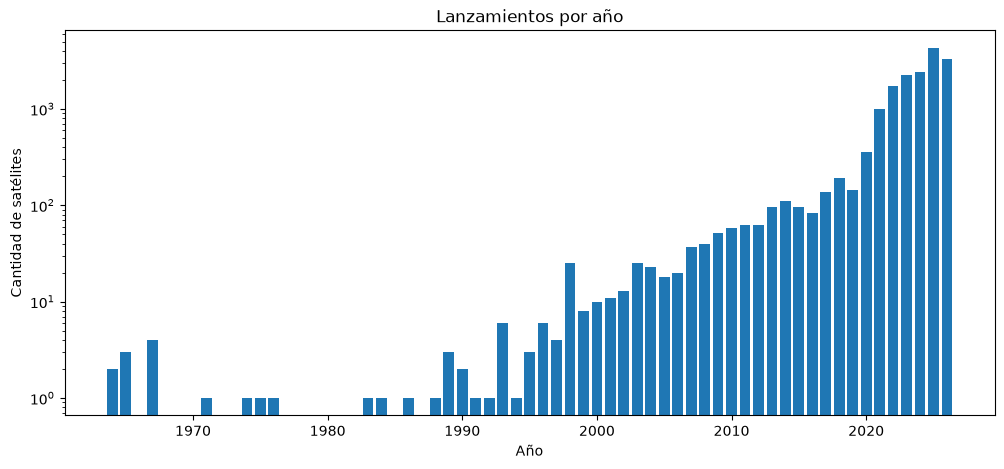

In [16]:
lanzamientos = lanzamientos_por_anio(registros)

barras_lanzamientos(lanzamientos, "lanzamientos.png")

In [17]:
def barras_apiladas(lanzamientos_a, lanzamientos_b, etiqueta_a, etiqueta_b, archivo):
    """
    Genera un gráfico de barras apiladas con dos grupos
    de lanzamientos por año.
    """

    anios = sorted(set(lanzamientos_a) | set(lanzamientos_b))

    cantidades_a = []
    cantidades_b = []

    for anio in anios:
        cantidades_a.append(lanzamientos_a.get(anio, 0))
        cantidades_b.append(lanzamientos_b.get(anio, 0))

    plt.figure(figsize=(12, 5))

    plt.bar(anios, cantidades_a, label=etiqueta_a)
    plt.bar(anios, cantidades_b, bottom=cantidades_a, label=etiqueta_b)

    plt.title("Lanzamientos por año: comparación entre grupos")
    plt.xlabel("Año")
    plt.ylabel("Cantidad de satélites")
    plt.legend()

    plt.savefig(f"salidas/{archivo}")
    plt.show()

In [20]:
# Separar los registros
registros_starlink = []
registros_resto = []

for registro in registros:
    nombre = registro["OBJECT_NAME"]

    if grupo(nombre) == "Starlink":
        registros_starlink.append(registro)
    else:
        registros_resto.append(registro)

# Obtener los lanzamientos por año
lanzamientos_starlink = lanzamientos_por_anio(registros_starlink)
lanzamientos_resto = lanzamientos_por_anio(registros_resto)

# Filtrar entre 1990 y 2026
lanzamientos_starlink = {
    anio: cantidad
    for anio, cantidad in lanzamientos_starlink.items()
    if 1990 <= anio <= 2026
}

lanzamientos_resto = {
    anio: cantidad
    for anio, cantidad in lanzamientos_resto.items()
    if 1990 <= anio <= 2026
}

print("Datos preparados correctamente")

Datos preparados correctamente


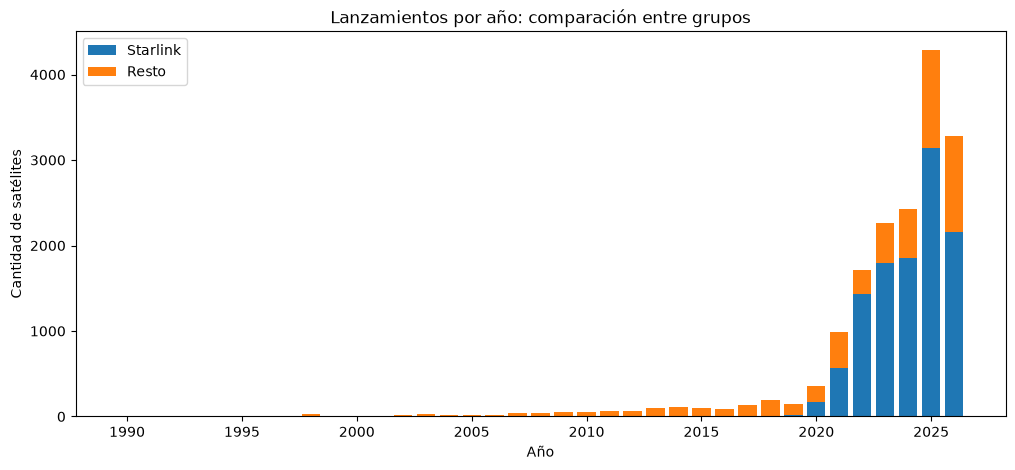

In [21]:
barras_apiladas(
    lanzamientos_starlink,
    lanzamientos_resto,
    "Starlink",
    "Resto",
    "starlink_vs_resto.png"
)